# Module 10 — Exercises — Solutions

These exercises follow the order of the concept guide: descriptive statistics, estimators and their bias,
standard errors and confidence intervals (including Wilson's), a coverage simulation, the bootstrap,
sample-size planning, the MSE decomposition, and finally the paired comparison of two classifiers.
Several checks compare your answer against a *hidden* value, so compute carefully rather than guessing.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Descriptive statistics from scratch  `★☆☆`

Implement five summaries using only `np.sort`, `np.sum`, `np.abs`, `np.floor`, `len` and indexing —
**not** `np.mean`, `np.median`, `np.var`, `np.std`, `np.quantile` or anything from `scipy.stats`
(those are used only in the checks):

* `my_mean(x)`;
* `my_median(x)` — the middle value for odd $n$, the average of the two middle values for even $n$;
* `my_var(x, ddof=0)` — $\frac{1}{n - \text{ddof}}\sum_i (x_i - \bar x)^2$;
* `my_mad(x)` — the median absolute deviation $\operatorname{median}_i\,|x_i - \operatorname{median}(x)|$ (unscaled);
* `my_trimmed_mean(x, alpha)` — drop the $\lfloor \alpha n \rfloor$ smallest and the $\lfloor \alpha n \rfloor$ largest values, average the rest.

All return Python floats. Test data: the ten response times from the guide (`times`), plus an even-length
and an odd-length vector.

In [3]:
times = np.array([120, 135, 140, 150, 155, 160, 170, 180, 210, 2400], dtype=float)
v_even = np.array([3., 1., 4., 1., 5., 9.])
v_odd = np.array([2., 7., 1., 8., 2., 8., 1.])


def my_mean(x):
    x = np.asarray(x, dtype=float)
    return float(np.sum(x) / len(x))

def my_median(x):
    s = np.sort(np.asarray(x, dtype=float)); n = len(s); m = n // 2
    return float(s[m]) if n % 2 else float(0.5 * (s[m - 1] + s[m]))

def my_var(x, ddof=0):
    x = np.asarray(x, dtype=float); mu = my_mean(x)
    return float(np.sum((x - mu) ** 2) / (len(x) - ddof))

def my_mad(x):
    x = np.asarray(x, dtype=float); m = my_median(x)
    return my_median(np.abs(x - m))

def my_trimmed_mean(x, alpha):
    s = np.sort(np.asarray(x, dtype=float)); k = int(np.floor(alpha * len(s)))
    return float(np.sum(s[k:len(s) - k]) / (len(s) - 2 * k))

**Check your answer:**

In [4]:
def _safe(fn, *args):
    try:
        return fn(*args)
    except Exception:
        return None
check_close('mean of times', _safe(my_mean, times), np.mean(times))
check_close('median of times (even n)', _safe(my_median, times), np.median(times))
check_close('median of an odd-length vector', _safe(my_median, v_odd), np.median(v_odd))
check_close('variance with divisor n', _safe(my_var, v_even, 0), np.var(v_even, ddof=0))
check_close('variance with divisor n-1', _safe(my_var, v_even, 1), np.var(v_even, ddof=1))
check_close('MAD of v_odd matches scipy', _safe(my_mad, v_odd), stats.median_abs_deviation(v_odd))
check_hash('hidden: MAD of times', _safe(my_mad, times), '0f7ceb2c4d1eba8c')
check_close('20% trimmed mean of v_even matches scipy', _safe(my_trimmed_mean, v_even, 0.20), stats.trim_mean(v_even, 0.20))
check_hash('hidden: 10% trimmed mean of times', _safe(my_trimmed_mean, times, 0.10), '3ec580618be4a937')
check('trimmed mean with alpha = 0 is the mean', (lambda a, b: a is not None and b is not None and abs(a - b) < 1e-9)(_safe(my_trimmed_mean, times, 0.0), _safe(my_mean, times)))

✅ mean of times
✅ median of times (even n)
✅ median of an odd-length vector
✅ variance with divisor n
✅ variance with divisor n-1
✅ MAD of v_odd matches scipy
✅ hidden: MAD of times
✅ 20% trimmed mean of v_even matches scipy
✅ hidden: 10% trimmed mean of times
✅ trimmed mean with alpha = 0 is the mean


True

**Why this works**

Sorting does all the work: the median reads off the middle of the sorted array (two middles for even
$n$), the trimmed mean slices off $k = \lfloor \alpha n \rfloor$ values at each end, and the MAD applies
the median twice. For `times` the mean is 382 while the median is 157.5, the 10%-trimmed mean 162.5 and
the MAD 20: the one outlier (2400 ms) moves the mean by more than 200 ms and the robust summaries by a few.
The common wrong turn in `my_var` is dividing by $n$ regardless of `ddof`, or computing deviations from the
median instead of the mean. Note that `np.var` defaults to `ddof=0` while pandas defaults to `ddof=1`.

## Exercise 2 — The biased and unbiased variance estimators  `★☆☆`

1. Implement `var_ddof(x, ddof)` $= \frac{1}{n - \text{ddof}}\sum_i (x_i - \bar x)^2$ (a float).
2. Implement `estimate_bias(estimator, n, n_reps, rng, true_value=1.0)`: draw `n_reps` samples of size
   `n` from $\mathcal N(0, 1)$ with `rng.normal(0.0, 1.0, size=(n_reps, n))`, apply `estimator` (a function
   of a 1-D array) to each row, and return the average estimate minus `true_value` — the Monte Carlo
   estimate of the bias.

With $n = 5$ the guide predicts a bias of $-\sigma^2/n = -0.2$ for `ddof=0` and $0$ for `ddof=1`.

In [5]:
def var_ddof(x, ddof):
    x = np.asarray(x, dtype=float)
    return float(((x - x.mean()) ** 2).sum() / (len(x) - ddof))

def estimate_bias(estimator, n, n_reps, rng, true_value=1.0):
    samples = rng.normal(0.0, 1.0, size=(n_reps, n))
    estimates = np.array([estimator(row) for row in samples])
    return float(estimates.mean() - true_value)

**Check your answer:**

In [6]:
try:
    got0 = var_ddof([1., 2., 3., 4.], 0); got1 = var_ddof([1., 2., 3., 4.], 1)
except Exception:
    got0 = got1 = None
check_close('var_ddof([1,2,3,4], 0) = 1.25', got0, 1.25)
check_close('var_ddof([1,2,3,4], 1) = 5/3', got1, 5 / 3)
try:
    b0 = estimate_bias(lambda s: var_ddof(s, 0), 5, 20_000, np.random.default_rng(1))
    b1 = estimate_bias(lambda s: var_ddof(s, 1), 5, 20_000, np.random.default_rng(1))
except Exception:
    b0 = b1 = None
check('bias of the ddof=0 estimator at n=5 is about -0.2', b0 is not None and -0.23 < b0 < -0.17, hint='expected -sigma^2/n = -0.2')
check('bias of the ddof=1 estimator is about 0', b1 is not None and -0.03 < b1 < 0.03)
try:
    bm = estimate_bias(lambda s: s.mean(), 5, 20_000, np.random.default_rng(2), true_value=0.0)
except Exception:
    bm = None
check('the sample mean is unbiased for the mean', bm is not None and abs(bm) < 0.02)

✅ var_ddof([1,2,3,4], 0) = 1.25
✅ var_ddof([1,2,3,4], 1) = 5/3
✅ bias of the ddof=0 estimator at n=5 is about -0.2
✅ bias of the ddof=1 estimator is about 0


✅ the sample mean is unbiased for the mean


True

**Why this works**

The deviations from $\bar x$ are smaller than the deviations from $\mu$ because $\bar x$ was chosen to
minimise them: $\mathbb E\sum(X_i - \bar X)^2 = (n - 1)\sigma^2$, so dividing by $n$ gives
$\mathbb E[\hat\sigma^2] = \frac{n-1}{n}\sigma^2$, a bias of $-\sigma^2/n = -0.2$ at $n = 5$, which the
simulation reproduces to within its Monte Carlo error of about $\sqrt{\operatorname{Var}(\hat\sigma^2)/20000} \approx 0.004$.
Dividing by $n - 1$ removes the bias exactly. The common wrong turn is to compute the bias of the
*standard deviation* instead — $s$ is not unbiased for $\sigma$ even with `ddof=1`.

## Exercise 3 — Standard error, z-interval and t-interval  `★☆☆`

For the eight assay readings `x_conc` implement

* `standard_error(x)` $= s/\sqrt n$ with $s$ the sample standard deviation (`ddof=1`);
* `z_interval(x, conf=0.95)` → the tuple `(lo, hi)` $= \bar x \pm z_{\alpha/2}\, s/\sqrt n$, using
  `stats.norm.ppf` for the quantile;
* `t_interval(x, conf=0.95)` → the same with $t_{n-1,\,\alpha/2}$ from `stats.t.ppf`.

The hidden checks hash the standard error to 4 decimals and the $z$-interval bounds to 3 decimals.

In [7]:
x_conc = np.array([12.1, 9.8, 11.4, 10.6, 12.9, 11.1, 10.2, 11.7])   # eight assay readings (mg/l)


def standard_error(x):
    x = np.asarray(x, dtype=float)
    return float(x.std(ddof=1) / np.sqrt(len(x)))

def z_interval(x, conf=0.95):
    x = np.asarray(x, dtype=float)
    z = stats.norm.ppf(0.5 + conf / 2)
    h = z * standard_error(x)
    return (float(x.mean() - h), float(x.mean() + h))

def t_interval(x, conf=0.95):
    x = np.asarray(x, dtype=float)
    t = stats.t.ppf(0.5 + conf / 2, df=len(x) - 1)
    h = t * standard_error(x)
    return (float(x.mean() - h), float(x.mean() + h))

**Check your answer:**

In [8]:
try:
    se = standard_error(x_conc)
except Exception:
    se = None
check_hash('hidden: standard error of x_conc', se, 'c098ef7598186e87', decimals=4)
check_close('SE matches scipy.stats.sem', se, stats.sem(x_conc))
try:
    lo, hi = z_interval(x_conc)
except Exception:
    lo = hi = None
check_hash('hidden: lower z bound', lo, '1af066729bb6a187', decimals=3)
check_hash('hidden: upper z bound', hi, '01d3b296abe67d69', decimals=3)
try:
    tlo, thi = t_interval(x_conc)
    ref = stats.t.interval(0.95, df=len(x_conc) - 1, loc=x_conc.mean(), scale=stats.sem(x_conc))
except Exception:
    tlo = thi = None; ref = (0.0, 0.0)
check_close('t-interval matches scipy.stats.t.interval', (tlo, thi), ref)
check('t-interval is wider than the z-interval', (tlo is not None and lo is not None) and (thi - tlo) > (hi - lo))
try:
    lo99, hi99 = z_interval(x_conc, conf=0.99)
except Exception:
    lo99 = hi99 = None
check('99% interval is wider than 95%', lo99 is not None and (hi99 - lo99) > (hi - lo))

✅ hidden: standard error of x_conc
✅ SE matches scipy.stats.sem
✅ hidden: lower z bound
✅ hidden: upper z bound
✅ t-interval matches scipy.stats.t.interval
✅ t-interval is wider than the z-interval
✅ 99% interval is wider than 95%


True

**Why this works**

$\bar x = 11.225$, $s = 1.022$, so the standard error is $1.022/\sqrt 8 = 0.361$. The $z$-interval is
$11.225 \pm 1.96 \times 0.361 = [10.517, 11.933]$. With only 8 observations the $t$ quantile is
$t_{7} = 2.365$ rather than 1.96, so the honest interval is about 21% wider: the $z$-interval pretends
that $s$ is $\sigma$. The common wrong turn is `ddof=0` in the standard deviation (too small by a factor
$\sqrt{7/8}$) or using `stats.norm.ppf(conf)` instead of `stats.norm.ppf(0.5 + conf/2)`, which gives a
one-sided quantile (1.645 for 95%).

## Exercise 4 — The Wilson score interval  `★★☆`

Implement `wilson_interval(k, n, conf=0.95)` for $k$ successes in $n$ trials, returning `(lo, hi)`:

$$\frac{\hat p + \frac{z^2}{2n}}{1 + \frac{z^2}{n}} \;\pm\; \frac{z}{1 + \frac{z^2}{n}}\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}, \qquad \hat p = k/n,\; z = z_{\alpha/2}.$$

Also implement the plain `wald_interval(k, n, conf=0.95)` $= \hat p \pm z\sqrt{\hat p(1-\hat p)/n}$ so you can
compare. The checks compare against `scipy.stats.binomtest(k, n).proportion_ci(method="wilson")` and probe
the boundary cases $k = 0$ and $k = n$.

In [9]:
def wilson_interval(k, n, conf=0.95):
    z = stats.norm.ppf(0.5 + conf / 2); z2 = z * z
    p = k / n
    centre = (p + z2 / (2 * n)) / (1 + z2 / n)
    half = (z / (1 + z2 / n)) * np.sqrt(p * (1 - p) / n + z2 / (4 * n * n))
    return (float(centre - half), float(centre + half))

def wald_interval(k, n, conf=0.95):
    z = stats.norm.ppf(0.5 + conf / 2); p = k / n
    h = z * np.sqrt(p * (1 - p) / n)
    return (float(p - h), float(p + h))

**Check your answer:**

In [10]:
def _sp(k, n, conf=0.95):
    ci = stats.binomtest(k, n).proportion_ci(confidence_level=conf, method="wilson")
    return (ci.low, ci.high)
def _safe(fn, *a, **kw):
    try:
        return fn(*a, **kw)
    except Exception:
        return None
check_close('Wilson 9/200 matches scipy', _safe(wilson_interval, 9, 200), _sp(9, 200))
check_close('Wilson 0/20 matches scipy', _safe(wilson_interval, 0, 20), _sp(0, 20))
check_close('Wilson 20/20 matches scipy', _safe(wilson_interval, 20, 20), _sp(20, 20))
check_close('Wilson 141/150 matches scipy', _safe(wilson_interval, 141, 150), _sp(141, 150))
check_close('Wilson 2/150 at 99% matches scipy', _safe(wilson_interval, 2, 150, conf=0.99), _sp(2, 150, 0.99))
w0 = _safe(wilson_interval, 0, 20)
check('Wilson lower bound at k = 0 is 0 and the upper bound is positive', w0 is not None and abs(w0[0]) < 1e-9 and 0.1 < w0[1] < 0.2)
wd = _safe(wald_interval, 0, 20)
check('Wald interval at k = 0 has zero width (that is the problem)', wd is not None and abs(wd[1] - wd[0]) < 1e-12)
wd2 = _safe(wald_interval, 2, 150)
check('Wald interval for 2/150 has a negative lower bound', wd2 is not None and wd2[0] < 0)

✅ Wilson 9/200 matches scipy
✅ Wilson 0/20 matches scipy
✅ Wilson 20/20 matches scipy
✅ Wilson 141/150 matches scipy
✅ Wilson 2/150 at 99% matches scipy
✅ Wilson lower bound at k = 0 is 0 and the upper bound is positive
✅ Wald interval at k = 0 has zero width (that is the problem)
✅ Wald interval for 2/150 has a negative lower bound


True

**Why this works**

Wilson keeps the unknown $p$ inside the standard error and solves $|\hat p - p| \le z\sqrt{p(1-p)/n}$ as a
quadratic in $p$; the two roots are the interval. Its centre $(\hat p + z^2/2n)/(1 + z^2/n)$ is pulled toward
$1/2$, which is what gives it a positive upper bound at $k = 0$ (about $z^2/(n + z^2) = 0.161$ for $n = 20$,
the rule of three in disguise) and keeps it inside $[0, 1]$ at $k = n$. The Wald interval plugs $\hat p$ into
the SE, so at $k = 0$ it collapses to $[0, 0]$ and for $2/150$ it dips below zero. The usual bug is to forget
the factor $1/(1 + z^2/n)$ on the half-width or to use $z^2/(4n)$ instead of $z^2/(4n^2)$ under the root.

## Exercise 5 — A coverage experiment  `★★☆`

Two interval procedures are given below (do not change them). Implement

`coverage(make_interval, n, mu, sigma, n_reps, rng)`

which draws `n_reps` samples of size `n` from $\mathcal N(\mu, \sigma^2)$ with `rng.normal(mu, sigma, size=n)`,
calls `make_interval(x)` on each to get `(lo, hi)`, and returns the fraction of intervals with
`lo <= mu <= hi` (a float). Then predict before you run: at $n = 4$, what coverage does the $z$-with-$s$
interval achieve? (The guide says $2F_{t_3}(1.96) - 1$.) And at $n = 30$?

In [11]:
def interval_z_with_s(x, conf=0.95):          # the common mistake: z quantile, estimated s
    z = stats.norm.ppf(0.5 + conf / 2); h = z * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean() - h, x.mean() + h

def interval_t(x, conf=0.95):                 # the correct small-sample interval
    t = stats.t.ppf(0.5 + conf / 2, df=len(x) - 1); h = t * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean() - h, x.mean() + h


def coverage(make_interval, n, mu, sigma, n_reps, rng):
    hits = 0
    for _ in range(n_reps):
        x = rng.normal(mu, sigma, size=n)
        lo, hi = make_interval(x)
        hits += (lo <= mu <= hi)
    return hits / n_reps

**Check your answer:**

In [12]:
try:
    cz = coverage(interval_z_with_s, 4, 10.0, 2.0, 20_000, np.random.default_rng(123))
    ct = coverage(interval_t, 4, 10.0, 2.0, 20_000, np.random.default_rng(123))
    cz30 = coverage(interval_z_with_s, 30, 10.0, 2.0, 20_000, np.random.default_rng(5))
except Exception:
    cz = ct = cz30 = None
check('coverage returns a float in [0, 1]', isinstance(cz, float) and 0.0 <= cz <= 1.0)
check('t-interval at n = 4 covers about 95%', ct is not None and 0.94 < ct < 0.96, hint='expected ~0.95')
check('z-with-s at n = 4 covers only about 85-86%', cz is not None and 0.84 < cz < 0.87, hint='expected 2*F_t3(1.96)-1 = 0.855')
check('z-with-s at n = 30 is nearly fine (about 94%)', cz30 is not None and 0.93 < cz30 < 0.955)
try:
    always = coverage(lambda x: (-np.inf, np.inf), 4, 10.0, 2.0, 100, np.random.default_rng(0))
except Exception:
    always = None
check_close('an infinite interval covers 100%', always, 1.0)

✅ coverage returns a float in [0, 1]
✅ t-interval at n = 4 covers about 95%
✅ z-with-s at n = 4 covers only about 85-86%
✅ z-with-s at n = 30 is nearly fine (about 94%)
✅ an infinite interval covers 100%


True

**Why this works**

Coverage is just a Monte Carlo estimate of $P(L \le \mu \le U)$: simulate, count, divide. The $t$-interval
achieves its nominal 95% at every $n$ because the $t$ quantile was built for exactly this situation; the
$z$-with-$s$ interval reaches only $2F_{t_3}(1.96) - 1 \approx 0.855$ at $n = 4$, because $s$ is a noisy
stand-in for $\sigma$ and 1.96 is too small a multiplier (the right one is $t_3 = 3.18$). By $n = 30$ the
two quantiles differ by 4% and the coverage gap has mostly closed. With 20,000 repetitions the Monte Carlo
standard error of a coverage estimate near 0.95 is $\sqrt{0.95 \times 0.05/20000} \approx 0.0015$, so the
check ranges are generous. A common wrong turn is to test `lo <= x.mean() <= hi`, which is always true.

## Exercise 6 — A general bootstrap percentile interval  `★★☆`

Implement `bootstrap_ci(x, stat, B, rng, conf=0.95)` returning the tuple `(lo, hi, se)`:

* draw `B` bootstrap samples of size $n$ from `x` *with replacement* (e.g. `rng.integers(0, n, size=(B, n))`
  as index arrays, or `rng.choice(x, size=n, replace=True)` in a loop);
* apply `stat` (a function of a 1-D array, e.g. `np.median`) to each;
* `lo, hi` are the $\frac{1-\text{conf}}{2}$ and $\frac{1+\text{conf}}{2}$ quantiles of the replicates (`np.quantile`),
  `se` is their standard deviation (`ddof=1`).

Apply it to the 30 request latencies `lat30` for the median (the checks use `B = 2000` and a fresh
`np.random.default_rng(0)`; exact values depend on how you draw, so the checks test ranges) and for the
mean, where the bootstrap SE should agree with the plug-in formula $\hat\sigma/\sqrt n$ (with `ddof=0`)
to within about 10%.

In [13]:
lat30 = np.array([152.6, 296.0, 276.7, 116.2, 129.2, 115.2, 199.4, 145.9, 217.9, 59.6,
                  328.3, 142.9, 210.8, 140.1, 124.1, 189.1, 226.5, 135.6, 139.0, 211.3,
                  97.1, 70.3, 182.8, 107.3, 57.4, 99.8, 118.7, 82.6, 71.1, 152.8])   # 30 request latencies (ms)


def bootstrap_ci(x, stat, B, rng, conf=0.95):
    x = np.asarray(x, dtype=float); n = len(x)
    idx = rng.integers(0, n, size=(B, n))
    replicates = np.array([stat(x[row]) for row in idx])
    lo, hi = np.quantile(replicates, [(1 - conf) / 2, (1 + conf) / 2])
    return (float(lo), float(hi), float(replicates.std(ddof=1)))

**Check your answer:**

In [14]:
try:
    lo, hi, se = bootstrap_ci(lat30, np.median, 2000, np.random.default_rng(0))
except Exception:
    lo = hi = se = None
check('median: lower bound in a plausible range (110-125 ms)', lo is not None and 110 < lo < 125)
check('median: upper bound in a plausible range (160-180 ms)', hi is not None and 160 < hi < 180)
check('median: bootstrap SE about 11-13 ms', se is not None and 10 < se < 14)
check('interval contains the sample median', lo is not None and lo <= np.median(lat30) <= hi)
try:
    mlo, mhi, mse = bootstrap_ci(lat30, np.mean, 2000, np.random.default_rng(0))
    ratio = mse / (lat30.std(ddof=0) / np.sqrt(len(lat30)))
except Exception:
    mlo = mhi = mse = ratio = None
check('mean: bootstrap SE within 12% of sigma_hat/sqrt(n)', ratio is not None and 0.88 < ratio < 1.12)
check('mean: interval roughly symmetric about the sample mean', mlo is not None and abs((mhi - lat30.mean()) - (lat30.mean() - mlo)) < 0.5 * mse)
try:
    wlo, whi, _ = bootstrap_ci(lat30, np.median, 2000, np.random.default_rng(0), conf=0.80)
except Exception:
    wlo = whi = None
check('an 80% interval is narrower than the 95% one', wlo is not None and (whi - wlo) < (hi - lo))

✅ median: lower bound in a plausible range (110-125 ms)
✅ median: upper bound in a plausible range (160-180 ms)
✅ median: bootstrap SE about 11-13 ms
✅ interval contains the sample median
✅ mean: bootstrap SE within 12% of sigma_hat/sqrt(n)
✅ mean: interval roughly symmetric about the sample mean
✅ an 80% interval is narrower than the 95% one


True

**Why this works**

The empirical distribution stands in for the population, so resampling rows of indices with replacement
and recomputing the statistic simulates the sampling distribution; quantiles of the replicates give the
percentile interval and their standard deviation the bootstrap SE. For the mean this reproduces the plug-in
formula $\hat\sigma_n/\sqrt n$ (divisor $n$, not $n - 1$, because the bootstrap resamples from $\hat F_n$),
which is the standard unit test for bootstrap code. For the median of 30 right-skewed latencies the
interval is noticeably asymmetric — the bootstrap captures that for free. Two classic bugs: sampling
*without* replacement (every replicate is then a permutation and the statistic never changes), and
resampling `B` values instead of `n`.

## Exercise 7 — Sample-size planning  `★★☆`

Implement two planners that return the smallest **integer** $n$ (round *up* with `np.ceil`, return `int`):

* `n_for_mean(sigma, e, conf=0.95)` $= \lceil (z_{\alpha/2}\,\sigma/e)^2 \rceil$ — the sample size that makes
  the $(1-\alpha)$ interval for a mean have half-width at most $e$;
* `n_for_proportion(e, conf=0.95, p=0.5)` $= \lceil z_{\alpha/2}^2\,p(1-p)/e^2 \rceil$, with $p = 0.5$ as the
  worst-case default.

Take $z_{\alpha/2}$ from `stats.norm.ppf(0.5 + conf / 2)` rather than typing 1.96 — a rounded quantile can
change the integer answer.

Then answer (the hidden checks hash the integers): how many deliveries to estimate a mean delivery time
to ± 2 minutes if $\sigma \approx 15$? How many respondents for a poll to ± 3 points, and to ± 1 point?
How many test images to estimate an accuracy near 90% to ± 1 point?

In [15]:
def n_for_mean(sigma, e, conf=0.95):
    z = stats.norm.ppf(0.5 + conf / 2)
    return int(np.ceil((z * sigma / e) ** 2))

def n_for_proportion(e, conf=0.95, p=0.5):
    z = stats.norm.ppf(0.5 + conf / 2)
    return int(np.ceil(z * z * p * (1 - p) / e ** 2))

**Check your answer:**

In [16]:
def _safe(fn, *a, **kw):
    try:
        return fn(*a, **kw)
    except Exception:
        return None
check_hash('hidden: deliveries for +/- 2 min with sigma 15', _safe(n_for_mean, 15, 2), '16badfc6202cb3f8')
check_hash('hidden: deliveries for +/- 1 min', _safe(n_for_mean, 15, 1), '8b6cd7c429e83373')
check_hash('hidden: poll to +/- 3 points (worst case p)', _safe(n_for_proportion, 0.03), '0f0b82fae280ae9f')
check_hash('hidden: test images for accuracy near 0.9 to +/- 1 point', _safe(n_for_proportion, 0.01, p=0.9), 'ee43ec7cc83b9a0f')
check_hash('hidden: poll to +/- 3 points at 99% confidence', _safe(n_for_proportion, 0.03, conf=0.99), '8b7a686fc953486d')
check('results are Python ints', isinstance(_safe(n_for_mean, 15, 2), int) and isinstance(_safe(n_for_proportion, 0.03), int))
r1, r2 = _safe(n_for_proportion, 0.01), _safe(n_for_proportion, 0.02)
check('halving the margin roughly quadruples n', r1 is not None and r2 is not None and 3.9 < r1 / r2 < 4.1)

✅ hidden: deliveries for +/- 2 min with sigma 15
✅ hidden: deliveries for +/- 1 min
✅ hidden: poll to +/- 3 points (worst case p)
✅ hidden: test images for accuracy near 0.9 to +/- 1 point
✅ hidden: poll to +/- 3 points at 99% confidence
✅ results are Python ints
✅ halving the margin roughly quadruples n


True

**Why this works**

Set the half-width $z\,\sigma/\sqrt n$ (or $z\sqrt{p(1-p)/n}$) equal to $e$ and solve for $n$, then round
up because a fraction of an observation does not exist. Delivery times: $(1.96 \times 15/2)^2 = 216.1 \to 217$;
to ± 1 minute, 865 — four times as many for half the margin. The poll: $0.9604/0.0009 = 1067.1 \to 1068$,
the origin of the "thousand-person poll"; ± 1 point needs 9,604. An accuracy near 0.9 to ± 1 point needs
$3.8415 \times 0.09/0.0001 = 3457.3 \to 3458$ images. At 99% confidence $z = 2.576$ and the poll needs 1,844.
The common wrong turn is rounding to the nearest integer (217 vs 216 would fail the precision target) or
quoting the margin as a full width instead of a half-width.

## Exercise 8 — Reading intervals and choosing estimators  `★★☆`

Three short questions; write your answers down before opening the model answer.

1. A product manager reads "the 95% confidence interval for the conversion rate is $[2.1\%, 3.4\%]$" and
   says: "So there is a 95% probability that the true rate is between 2.1% and 3.4%." What is wrong with
   this sentence, what is the correct frequentist reading, and under what additional assumption would the
   manager's sentence become literally true?
2. On a sample of 20 user sessions none crashed. A colleague reports "crash rate 0% (95% CI: 0% to 0%)".
   Diagnose the error and give a defensible upper bound.
3. For normal data the sample mean has lower MSE than the sample median; for Laplace or Student-$t_3$ data
   the median wins. Explain *why* in terms of the two ingredients of the MSE, and name the property of the
   data that decides.

**Answer**

1. Once the interval is computed, nothing is random: the true rate is a fixed number that is either inside
   $[2.1\%, 3.4\%]$ or not. The 95% is a property of the *procedure* — over many repeated samples, 95% of the
   intervals it produces contain the truth — so the honest sentence is "this interval was produced by a method
   that captures the true rate 95% of the time". To make a probability statement about the rate itself you
   need a prior distribution for it; the Bayesian credible interval then has exactly the manager's reading
   (Module 11), and with a flat prior and this much data it is numerically almost the same interval.
2. The colleague used the Wald interval $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$ with $\hat p = 0$, which has
   zero width — it plugs the estimate into its own standard error, and the estimate happens to be at the
   boundary. Twenty crash-free sessions are perfectly consistent with a crash rate of several percent: the
   Wilson interval gives $[0, z^2/(n + z^2)] = [0, 0.161]$, the rule of three gives an upper bound of about
   $3/20 = 0.15$, and the exact (Clopper–Pearson) 95% one-sided bound is $1 - 0.05^{1/20} \approx 0.139$.
3. Both estimators are unbiased for a symmetric population, so the MSE *is* the variance. The variance of the
   mean is $\sigma^2/n$, driven by the tails (large deviations are squared); the variance of the median is
   $\approx 1/(4f(m)^2 n)$, driven only by how much probability mass sits near the centre. Light tails and a
   flat centre (normal) favour the mean; heavy tails with a sharp peak (Laplace, $t_3$) favour the median,
   because the extra tail mass inflates $\sigma^2$ but not $f(m)$. For the Cauchy distribution $\sigma^2$ is
   infinite and the mean does not converge at all, while the median behaves perfectly well. The deciding
   property is the tail weight of the data-generating distribution.

## Exercise 9 — Bias, variance and MSE by simulation  `★★★`

1. Implement `mse_decomposition(estimates, theta)`: given a 1-D array of estimates (many realisations of
   one estimator) and the true value `theta`, return the dict
   `{"bias": mean(estimates) - theta, "var": var(estimates), "mse": mean((estimates - theta)^2)}`
   (use `ddof=0` for the variance, so that the identity $\text{mse} = \text{bias}^2 + \text{var}$ holds exactly).
2. Implement `compare_variance_estimators(n, n_reps, rng, sigma2=1.0)`: draw `n_reps` samples of size `n`
   from $\mathcal N(0, \sigma^2)$ with `rng.normal(0.0, np.sqrt(sigma2), size=(n_reps, n))`, compute the sum of
   squared deviations from each sample's mean, and return a dict with keys `"n-1"`, `"n"`, `"n+1"` mapping to
   the `mse_decomposition` of $\hat\sigma^2 = \text{SS}/\text{divisor}$ against `sigma2`.

With $n = 10$ the guide's table predicts MSEs of about 0.222, 0.190 and 0.182 and biases $0, -0.1, -0.182$.
Which estimator would you use if MSE is what you care about?

In [17]:
def mse_decomposition(estimates, theta):
    estimates = np.asarray(estimates, dtype=float)
    bias = float(estimates.mean() - theta)
    var = float(estimates.var())                      # divisor n_reps: the Monte Carlo variance of the estimator
    mse = float(((estimates - theta) ** 2).mean())
    return {"bias": bias, "var": var, "mse": mse}

def compare_variance_estimators(n, n_reps, rng, sigma2=1.0):
    X = rng.normal(0.0, np.sqrt(sigma2), size=(n_reps, n))
    ss = ((X - X.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
    out = {}
    for name, divisor in (("n-1", n - 1), ("n", n), ("n+1", n + 1)):
        out[name] = mse_decomposition(ss / divisor, sigma2)
    return out

**Check your answer:**

In [18]:
try:
    dec = mse_decomposition(np.array([1.0, 2.0, 4.0]), 2.0)
    ok_keys = set(dec) == {"bias", "var", "mse"}
except Exception:
    dec, ok_keys = None, False
check('returns a dict with keys bias, var, mse', ok_keys)
check_close('bias of [1, 2, 4] about theta = 2 is 1/3', (dec["bias"] if ok_keys else None), 1 / 3)
check_close('mse = bias^2 + var exactly', (dec["mse"] if ok_keys else None), (dec["bias"] ** 2 + dec["var"] if ok_keys else None), tol=1e-12)
try:
    res = compare_variance_estimators(10, 50_000, np.random.default_rng(7))
    m1, m0, m2 = res["n-1"]["mse"], res["n"]["mse"], res["n+1"]["mse"]
    b1, b0, b2 = res["n-1"]["bias"], res["n"]["bias"], res["n+1"]["bias"]
except Exception:
    m1 = m0 = m2 = b1 = b0 = b2 = None
check('n-1: bias about 0', b1 is not None and abs(b1) < 0.015)
check('n: bias about -0.1', b0 is not None and -0.115 < b0 < -0.085)
check('n-1: MSE about 0.222', m1 is not None and 0.205 < m1 < 0.24)
check('n+1: MSE about 0.182', m2 is not None and 0.17 < m2 < 0.195)
check('MSE ordering n-1 > n > n+1 (the unbiased estimator loses)', m1 is not None and m1 > m0 > m2)

✅ returns a dict with keys bias, var, mse
✅ bias of [1, 2, 4] about theta = 2 is 1/3
✅ mse = bias^2 + var exactly
✅ n-1: bias about 0
✅ n: bias about -0.1
✅ n-1: MSE about 0.222
✅ n+1: MSE about 0.182
✅ MSE ordering n-1 > n > n+1 (the unbiased estimator loses)


True

**Why this works**

`mse_decomposition` is the identity $\mathbb E[(\hat\theta - \theta)^2] = \operatorname{Var}(\hat\theta) +
(\mathbb E\hat\theta - \theta)^2$ evaluated on Monte Carlo draws; with the population-style variance
(`ddof=0`) it holds to machine precision, with `ddof=1` only approximately. For the variance estimators,
$\text{SS} = \sum(X_i - \bar X)^2 \sim \sigma^2\chi^2_{n-1}$ has mean $(n-1)\sigma^2$ and variance
$2(n-1)\sigma^4$, so $\text{SS}/c$ has bias $(n-1)/c - 1$ and variance $2(n-1)/c^2$: dividing by $n + 1$
minimises the MSE within this family (0.182 vs 0.222 for the unbiased choice at $n = 10$). If MSE is the goal,
unbiasedness is not sacred — shrinking toward zero pays. The common wrong turn is to compute the sum of
squares around the *true* mean 0 instead of the sample mean, which removes the bias entirely (and the lesson).

## Exercise 10 — Comparing two classifiers on the same test set  `★★★`

Two classifiers are scored on the same $n$ test examples; `correct_a[i]` and `correct_b[i]` say whether
each got example $i$ right. Implement `paired_accuracy_diff(correct_a, correct_b, conf=0.95)` returning a
dict with

* `"n10"`: the number of examples A gets right and B wrong; `"n01"`: the reverse;
* `"d"`: the accuracy difference $\hat d = (n_{10} - n_{01})/n$;
* `"se_paired"` $= \sqrt{\frac1n\big(\frac{n_{10} + n_{01}}{n} - \hat d^{\,2}\big)}$ — the standard error of the
  mean of the per-example differences $c^A_i - c^B_i \in \{-1, 0, 1\}$ (plug-in variance, divisor $n$);
* `"se_unpaired"` $= \sqrt{\hat a_A(1 - \hat a_A)/n + \hat a_B(1 - \hat a_B)/n}$ — what you would (wrongly) get by
  treating the two accuracies as independent;
* `"ci"`: the tuple $\hat d \pm z_{\alpha/2}\,\text{se}_{\text{paired}}$.

Run it on `(correct_a, correct_b)` and on `(correct_c, correct_d)`. Both pairs have accuracies about 1–2
points apart; which difference is statistically clear, and why?

In [19]:
# per-example correctness of two classifiers on the same 1000 test examples
correct_a = np.r_[np.ones(700), np.ones(90), np.zeros(70), np.zeros(140)].astype(bool)
correct_b = np.r_[np.ones(700), np.zeros(90), np.ones(70), np.zeros(140)].astype(bool)
# a second pair that disagrees on far fewer examples
correct_c = np.r_[np.ones(700), np.ones(15), np.zeros(3), np.zeros(282)].astype(bool)
correct_d = np.r_[np.ones(700), np.zeros(15), np.ones(3), np.zeros(282)].astype(bool)


def paired_accuracy_diff(correct_a, correct_b, conf=0.95):
    a = np.asarray(correct_a, dtype=bool); b = np.asarray(correct_b, dtype=bool); n = len(a)
    n10 = int((a & ~b).sum()); n01 = int((~a & b).sum())
    d = (n10 - n01) / n
    se_paired = float(np.sqrt(((n10 + n01) / n - d ** 2) / n))
    pa, pb = a.mean(), b.mean()
    se_unpaired = float(np.sqrt(pa * (1 - pa) / n + pb * (1 - pb) / n))
    z = stats.norm.ppf(0.5 + conf / 2)
    return {"d": float(d), "n10": n10, "n01": n01, "se_paired": se_paired, "se_unpaired": se_unpaired,
            "ci": (float(d - z * se_paired), float(d + z * se_paired))}

**Check your answer:**

In [20]:
try:
    r = paired_accuracy_diff(correct_a, correct_b)
    d, sep, seu, ci, n10, n01 = r["d"], r["se_paired"], r["se_unpaired"], r["ci"], r["n10"], r["n01"]
except Exception:
    d = sep = seu = ci = n10 = n01 = None
check('n10 = 90 and n01 = 70', n10 == 90 and n01 == 70)
check_close('d = 0.02', d, 0.02)
check_hash('hidden: paired SE', sep, '409fca23cb12b095', decimals=4)
check_hash('hidden: unpaired SE', seu, 'df966b38d308909d', decimals=4)
check('paired SE is smaller than unpaired SE', sep is not None and seu is not None and sep < seu)
check_hash('hidden: lower CI bound', (ci[0] if ci is not None else None), '0e52206a94cb8023', decimals=3)
check_hash('hidden: upper CI bound', (ci[1] if ci is not None else None), '2d6a7bc98779e539', decimals=3)
try:
    r2 = paired_accuracy_diff(correct_c, correct_d)
    sep2, ci2 = r2["se_paired"], r2["ci"]
except Exception:
    sep2 = ci2 = None
check_hash('hidden: paired SE for the second pair', sep2, '713dfee71e8d159c', decimals=4)
check('second pair: the interval excludes 0 (a clear difference despite a smaller d)', ci2 is not None and ci2[0] > 0)
check('first pair: the interval includes 0 (inconclusive)', ci is not None and ci[0] < 0 < ci[1])

✅ n10 = 90 and n01 = 70
✅ d = 0.02
✅ hidden: paired SE
✅ hidden: unpaired SE
✅ paired SE is smaller than unpaired SE
✅ hidden: lower CI bound
✅ hidden: upper CI bound
✅ hidden: paired SE for the second pair
✅ second pair: the interval excludes 0 (a clear difference despite a smaller d)
✅ first pair: the interval includes 0 (inconclusive)


True

**Why this works**

The per-example difference $d_i = c^A_i - c^B_i$ is $+1$ on the $n_{10}$ examples, $-1$ on the $n_{01}$, and
$0$ wherever the models agree, so its mean is $\hat d$ and its plug-in variance is
$\frac{n_{10} + n_{01}}{n} - \hat d^{\,2}$; the standard error of the mean follows by dividing by $n$ and
taking the root. Only the disagreements contribute. For the first pair ($90$ vs $70$ of $1000$) the paired SE is
0.0126 versus 0.0185 unpaired, and the interval $[-0.005, 0.045]$ still includes zero. The second pair differs
by only 1.2 points, but the models disagree on just 18 examples: the paired SE is 0.0042 and the interval
$[0.004, 0.020]$ excludes zero — a smaller difference, yet a clearer one. The unpaired formula cannot see this
because it ignores that both models are graded on the same questions. The common bug is to divide the
variance by $n - 1$ or to compute `se_paired` from the two marginal accuracies.

## Exercise 11 — Mini-project: honest error bars for two classifiers  `★★★`

Evaluate two classifiers on a held-out half of `load_breast_cancer` and report their performance the way
this module says it should be reported.

**Setup.** Split with `train_test_split(X, y, test_size=0.5, random_state=0, stratify=y)`; standardise
with the training half's mean and standard deviation. Model A: the **nearest-centroid** classifier from the
lesson (assign each test point to the class whose training-set centroid is closer in standardised space).
Model B: `sklearn.linear_model.LogisticRegression(max_iter=5000)` on the standardised features (or any
second classifier you like). Use `rng = np.random.default_rng(2024)` for the bootstrap.

**Deliverables**

1. For each model: test **accuracy** with its formula standard error $\sqrt{\hat a(1-\hat a)/n}$, a Wilson
   95% interval, and a bootstrap 95% percentile interval obtained by resampling the test *examples*
   ($B \ge 2000$).
2. For each model: test **F1 score** (computed by hand from TP, FP, FN) with a bootstrap SE and interval —
   there is no formula for this one.
3. A **paired** comparison: the accuracy difference B − A with the paired SE from the disagreement counts,
   the paired bootstrap interval for the accuracy difference *and* for the F1 difference (use the *same*
   resample indices for both models), and the unpaired SE for contrast.
4. **Sample-size planning**: how many test examples would be needed for a ± 2 point 95% interval on each
   accuracy, and on the difference (assume the observed disagreement rate)?
5. A figure overlaying the bootstrap distributions of the two models' accuracies (and F1), with title and
   axis labels.

Write two or three sentences of conclusion: is B better than A, and what would you need to be sure?

**Rubric — you have mastered this when you can:**

* The split, standardisation and both models are implemented correctly, with statistics computed on the training half only.
* Every reported metric carries an interval; the formula SE, Wilson and bootstrap intervals for accuracy agree to within a few tenths of a point.
* F1 is computed by hand and its bootstrap replicates reuse the same resampled indices as the accuracy replicates.
* The paired comparison uses the disagreement counts; the paired SE is smaller than the unpaired one and the paired bootstrap interval agrees with the paired formula.
* The sample-size answers follow from $n = z^2 \hat p(1-\hat p)/e^2$ (and the analogous formula for the difference), rounded up.
* The figure has a title, axis labels and a legend, and the conclusion distinguishes "B is better on this sample" from "B is better".

**Solution sketch**

With `random_state=0` the test half has 285 tumours. Nearest centroid reaches about 92% accuracy, logistic
regression about 98%; formula, Wilson and bootstrap intervals for each agree closely (roughly ± 3 points for A,
± 2 for B). F1 is a little above accuracy for both because the positive (benign) class is the majority. The
models disagree on 23 examples, 20 of them in B's favour, so the paired SE of the difference is about
1.7 points — only a little below the unpaired 1.8 here, because A's errors are mostly examples B gets
right, so the two models' mistakes are not strongly correlated — and the paired interval for B − A,
roughly $[+2.7, +9.2]$ points, excludes zero: B is better on this test set *and* the difference is
statistically clear. For a ± 2 point interval on B's accuracy you need about 200 examples (its accuracy is
high, so $p(1-p)$ is small); for A about 710; and for the *difference* about 740 at the observed
disagreement rate. The remaining caveat is not statistical: the 569 tumours are a
convenience sample from one institution, so the intervals describe sampling error, not generalisation to
other scanners or populations.

test set: n = 285, positives (benign = 1): 179

A: nearest centroid      accuracy 0.9193  SE 0.0161  Wilson [0.882, 0.946]  bootstrap [0.884, 0.951]
                         F1       0.9363  bootstrap SE 0.0133  bootstrap [0.908, 0.960]
B: logistic regression   accuracy 0.9789  SE 0.0085  Wilson [0.955, 0.990]  bootstrap [0.961, 0.993]
                         F1       0.9831  bootstrap SE 0.0069  bootstrap [0.968, 0.995]

disagreements: A right/B wrong 3, B right/A wrong 20, agree on 262
accuracy difference B - A = +0.0596   paired SE 0.0165  CI [+0.0274, +0.0919]   paired bootstrap CI [+0.0281, +0.0947]   unpaired SE 0.0182
F1 difference B - A = +0.0472   paired bootstrap CI [+0.0219, +0.0752]
n for a +/- 2 point 95% interval on the accuracy of A: nearest centroid: 713
n for a +/- 2 point 95% interval on the accuracy of B: logistic regression: 198
n for a +/- 2 point interval on the DIFFERENCE (same disagreement rate): 741
n for a +/- 1 point interval on the difference: 2964


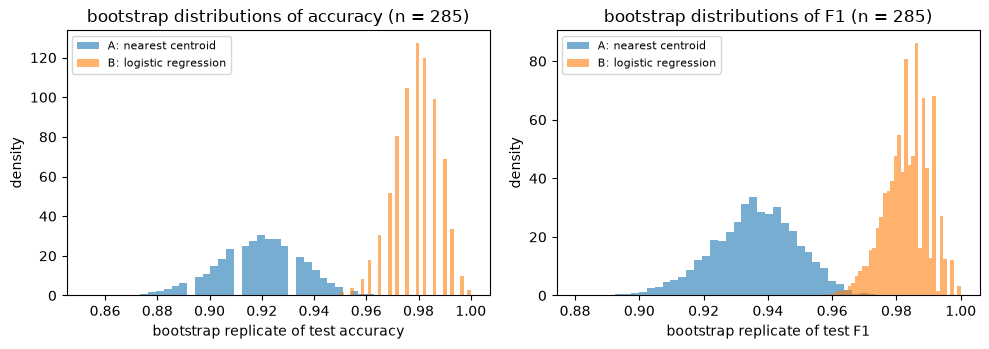

In [21]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(2024)
X_all, y_all = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.5, random_state=0, stratify=y_all)
n = len(y_te)
mu_tr, sd_tr = X_tr.mean(0), X_tr.std(0)
Z_tr, Z_te = (X_tr - mu_tr) / sd_tr, (X_te - mu_tr) / sd_tr

# model A: nearest centroid on standardised features; model B: logistic regression
c0, c1 = Z_tr[y_tr == 0].mean(0), Z_tr[y_tr == 1].mean(0)
pred_A = (((Z_te - c1) ** 2).sum(1) < ((Z_te - c0) ** 2).sum(1)).astype(int)
pred_B = LogisticRegression(max_iter=5000).fit(Z_tr, y_tr).predict(Z_te)

def accuracy(pred, y):
    return (pred == y).mean()

def f1_score_(pred, y):
    tp = ((pred == 1) & (y == 1)).sum(); fp = ((pred == 1) & (y == 0)).sum(); fn = ((pred == 0) & (y == 1)).sum()
    return 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0

def wilson(k, n, z=1.959964):
    p = k / n; z2 = z * z
    c = (p + z2 / (2 * n)) / (1 + z2 / n); h = z / (1 + z2 / n) * np.sqrt(p * (1 - p) / n + z2 / (4 * n * n))
    return c - h, c + h

B = 5000
idx = rng.integers(0, n, size=(B, n))                      # one set of resamples shared by both models (paired)
print(f"test set: n = {n}, positives (benign = 1): {y_te.sum()}\n")
results = {}
for name, pred in [("A: nearest centroid", pred_A), ("B: logistic regression", pred_B)]:
    acc = accuracy(pred, y_te); f1 = f1_score_(pred, y_te)
    boot_acc = np.array([accuracy(pred[i], y_te[i]) for i in idx])
    boot_f1 = np.array([f1_score_(pred[i], y_te[i]) for i in idx])
    results[name] = (acc, f1, boot_acc, boot_f1)
    k = int((pred == y_te).sum())
    print(f"{name:24s} accuracy {acc:.4f}  SE {np.sqrt(acc*(1-acc)/n):.4f}  Wilson [{wilson(k, n)[0]:.3f}, {wilson(k, n)[1]:.3f}]"
          f"  bootstrap [{np.quantile(boot_acc, 0.025):.3f}, {np.quantile(boot_acc, 0.975):.3f}]")
    print(f"{'':24s} F1       {f1:.4f}  bootstrap SE {boot_f1.std(ddof=1):.4f}  bootstrap [{np.quantile(boot_f1, 0.025):.3f}, {np.quantile(boot_f1, 0.975):.3f}]")

# paired comparison
cA, cB = pred_A == y_te, pred_B == y_te
n10, n01 = int((cA & ~cB).sum()), int((~cA & cB).sum())
d = (n01 - n10) / n                                        # B minus A
se_paired = np.sqrt(((n10 + n01) / n - d ** 2) / n)
se_unpaired = np.sqrt(cA.mean() * (1 - cA.mean()) / n + cB.mean() * (1 - cB.mean()) / n)
boot_d = results["B: logistic regression"][2] - results["A: nearest centroid"][2]
boot_df1 = results["B: logistic regression"][3] - results["A: nearest centroid"][3]
print(f"\ndisagreements: A right/B wrong {n10}, B right/A wrong {n01}, agree on {n - n10 - n01}")
print(f"accuracy difference B - A = {d:+.4f}   paired SE {se_paired:.4f}  CI [{d - 1.96*se_paired:+.4f}, {d + 1.96*se_paired:+.4f}]"
      f"   paired bootstrap CI [{np.quantile(boot_d, 0.025):+.4f}, {np.quantile(boot_d, 0.975):+.4f}]   unpaired SE {se_unpaired:.4f}")
print(f"F1 difference B - A = {boot_df1.mean():+.4f}   paired bootstrap CI [{np.quantile(boot_df1, 0.025):+.4f}, {np.quantile(boot_df1, 0.975):+.4f}]")

# how large a test set for +/- 2 points?
z = 1.959964
for name, (acc, _, _, _) in results.items():
    print(f"n for a +/- 2 point 95% interval on the accuracy of {name}: {int(np.ceil(z*z*acc*(1-acc)/0.02**2))}")
var_diff = (n10 + n01) / n - d ** 2
print(f"n for a +/- 2 point interval on the DIFFERENCE (same disagreement rate): {int(np.ceil(z*z*var_diff/0.02**2))}")
print(f"n for a +/- 1 point interval on the difference: {int(np.ceil(z*z*var_diff/0.01**2))}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (metric, j) in zip(axes, [("accuracy", 2), ("F1", 3)]):
    for name, res in results.items():
        ax.hist(res[j], bins=40, alpha=0.6, density=True, label=name)
    ax.set_xlabel(f"bootstrap replicate of test {metric}"); ax.set_ylabel("density"); ax.set_title(f"bootstrap distributions of {metric} (n = {n})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Score

In [22]:
summary()


Score: 67/67 checks passed  🎉
